In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# 1. MA'LUMOTLARNI YUKLASH

df = pd.read_csv("onlayn_dokon_savdo_xom.csv")

print("Dastlabki ma'lumotlar:")
print(df.head())

print("\nMa'lumotlar o'lchami:", df.shape)
print("\nUstunlar:")
print(df.columns.tolist())

print("\nMa'lumot turlari:")
print(df.dtypes)

Dastlabki ma'lumotlar:
  buyurtma_id                 sana   kategoriya  miqdor  birlik_narxi_uzs  \
0     ORD0001  2025-10-16 00:00:00  Elektronika       3          277000.0   
1     ORD0002  2024-08-16 00:00:00        Kiyim       2           99000.0   
2     ORD0003  2025-08-27 00:00:00        Sport       4          167000.0   
3     ORD0004  2024-08-26 00:00:00     Kitoblar       2           42000.0   
4     ORD0005  2025-10-27 00:00:00     Kitoblar       3           40000.0   

   chegirma_pct     hudud savdo_kanali  tushum_uzs  
0             0  Farg‘ona     Veb-sayt    831000.0  
1            10   Andijon     Veb-sayt    178200.0  
2             0  Toshkent     Veb-sayt    668000.0  
3            10   Andijon     Veb-sayt     75600.0  
4             5    Buxoro  Marketplace    114000.0  

Ma'lumotlar o'lchami: (604, 9)

Ustunlar:
['buyurtma_id', 'sana', 'kategoriya', 'miqdor', 'birlik_narxi_uzs', 'chegirma_pct', 'hudud', 'savdo_kanali', 'tushum_uzs']

Ma'lumot turlari:
buyurtma_id

In [3]:
# 2. MA'LUMOTLAR SIFATINI TEKSHIRISH

print("\nYetishmayotgan qiymatlar:")
print(df.isnull().sum())

print("\nTakroriy qatorlar:", df.duplicated().sum())
print("Takroriy buyurtmalar:", df["buyurtma_id"].duplicated().sum())



Yetishmayotgan qiymatlar:
buyurtma_id         0
sana                0
kategoriya          0
miqdor              0
birlik_narxi_uzs    5
chegirma_pct        0
hudud               8
savdo_kanali        0
tushum_uzs          0
dtype: int64

Takroriy qatorlar: 4
Takroriy buyurtmalar: 4


In [4]:
# 3. MA'LUMOTLARNI TOZALASH

df_clean = df.copy()

# Sanani to'g'ri formatga o'tkazish
df_clean["sana"] = pd.to_datetime(
    df_clean["sana"],
    errors="coerce"
)

# Kategoriya nomlarini tartibga keltirish
df_clean["kategoriya"] = (
    df_clean["kategoriya"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Hududdagi bo'sh qiymatlarni belgilash
df_clean["hudud"] = df_clean["hudud"].fillna("Noma'lum")

# Matn ustunlarini tozalash
df_clean["savdo_kanali"] = (
    df_clean["savdo_kanali"].astype("string").str.strip()
)

# Sonli ustunlarni to'g'ri turga o'tkazish
for col in ["miqdor", "birlik_narxi_uzs", "chegirma_pct"]:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# Takroriy buyurtmalarni olib tashlash
df_clean = df_clean.drop_duplicates(
    subset=["buyurtma_id"],
    keep="first"
)

# Sanasi noto'g'ri qatorlarni olib tashlash
df_clean = df_clean.dropna(subset=["sana"])

# Narxdagi bo'sh qiymatlarni kategoriya medianasi bilan to'ldirish
df_clean["birlik_narxi_uzs"] = (
    df_clean.groupby("kategoriya")["birlik_narxi_uzs"]
    .transform(lambda x: x.fillna(x.median()))
)

# Miqdordagi bo'sh qiymatlarni mediana bilan to'ldirish
df_clean["miqdor"] = df_clean["miqdor"].fillna(
    df_clean["miqdor"].median()
)

# Bo'sh chegirmani 0 deb olish
df_clean["chegirma_pct"] = df_clean["chegirma_pct"].fillna(0)

# Mantiqan noto'g'ri qiymatlarni chiqarish
df_clean = df_clean[
    (df_clean["miqdor"] > 0)
    & (df_clean["birlik_narxi_uzs"] > 0)
    & (df_clean["chegirma_pct"].between(0, 100))
].copy()

# Tushumni qayta hisoblash
df_clean["tushum_uzs"] = (
    df_clean["miqdor"]
    * df_clean["birlik_narxi_uzs"]
    * (1 - df_clean["chegirma_pct"] / 100)
)

print("\nXom ma'lumotlar:", len(df))
print("Tozalangan ma'lumotlar:", len(df_clean))

# Tozalangan datasetni saqlash
df_clean.to_csv(
    "onlayn_dokon_savdo_tozalangan.csv",
    index=False,
    encoding="utf-8-sig"
)



Xom ma'lumotlar: 604
Tozalangan ma'lumotlar: 597


In [5]:
# 4. TAVSIFIY STATISTIKA

ustunlar = [
    "miqdor",
    "birlik_narxi_uzs",
    "chegirma_pct",
    "tushum_uzs"
]

statistika = df_clean[ustunlar].describe().T

# Moda qiymatini hisoblash
statistika["moda"] = [
    df_clean[col].mode().iloc[0]
    for col in ustunlar
]

print("\nTavsifiy statistika:")
print(statistika.round(2))

statistika.to_csv(
    "tavsifiy_statistika.csv",
    encoding="utf-8-sig"
)



Tavsifiy statistika:
                  count       mean        std      min       25%       50%  \
miqdor            597.0       2.71       1.33      1.0       2.0       3.0   
birlik_narxi_uzs  597.0  151934.67   90484.27  30000.0   89000.0  145000.0   
chegirma_pct      597.0       6.38       6.47      0.0       0.0       5.0   
tushum_uzs        597.0  356456.28  257654.91  33250.0  174250.0  288900.0   

                       75%        max      moda  
miqdor                 3.0        8.0       2.0  
birlik_narxi_uzs  188000.0   417000.0   50000.0  
chegirma_pct          10.0       20.0       0.0  
tushum_uzs        469200.0  2052000.0  108000.0  


In [6]:
# 5. KATEGORIYALAR BO'YICHA TAHLIL

kategoriya_tahlili = df_clean.groupby("kategoriya").agg(
    buyurtmalar=("buyurtma_id", "count"),
    jami_miqdor=("miqdor", "sum"),
    jami_tushum=("tushum_uzs", "sum"),
    ortacha_chegirma=("chegirma_pct", "mean")
).sort_values("jami_tushum", ascending=False)

print("\nKategoriya bo'yicha natijalar:")
print(kategoriya_tahlili.round(2))

print(
    "\nEng katta tushumli kategoriya:",
    kategoriya_tahlili["jami_tushum"].idxmax()
)



Kategoriya bo'yicha natijalar:
             buyurtmalar  jami_miqdor  jami_tushum  ortacha_chegirma
kategoriya                                                          
Elektronika           95          215   64319000.0              6.37
Sport                139          321   54377400.0              6.55
Uy-Ro‘Zg‘Or          115          302   41067100.0              6.39
Kiyim                134          416   37421850.0              6.83
Kitoblar             114          366   15619050.0              5.66

Eng katta tushumli kategoriya: Elektronika


In [7]:
# 6. HUDUDLAR BO'YICHA TAHLIL

hudud_tahlili = df_clean.groupby("hudud").agg(
    buyurtmalar=("buyurtma_id", "count"),
    jami_tushum=("tushum_uzs", "sum")
).sort_values("jami_tushum", ascending=False)

print("\nHududlar bo'yicha natijalar:")
print(hudud_tahlili.round(2))


Hududlar bo'yicha natijalar:
           buyurtmalar  jami_tushum
hudud                              
Andijon            126   48338200.0
Toshkent           130   47253050.0
Samarqand          115   40827650.0
Farg‘ona           104   37123150.0
Buxoro             114   36145050.0
Noma'lum             8    3117300.0


In [8]:
# 7. KORRELYATSIYA TAHLILI

korrelyatsiya = df_clean[
    ["miqdor", "birlik_narxi_uzs", "chegirma_pct", "tushum_uzs"]
].corr()

print("\nKorrelyatsiya matritsasi:")
print(korrelyatsiya.round(3))

# Korrelyatsiya sabab-oqibat bog'liqligini isbotlamaydi.


Korrelyatsiya matritsasi:
                  miqdor  birlik_narxi_uzs  chegirma_pct  tushum_uzs
miqdor             1.000            -0.260        -0.009       0.436
birlik_narxi_uzs  -0.260             1.000        -0.003       0.654
chegirma_pct      -0.009            -0.003         1.000      -0.088
tushum_uzs         0.436             0.654        -0.088       1.000


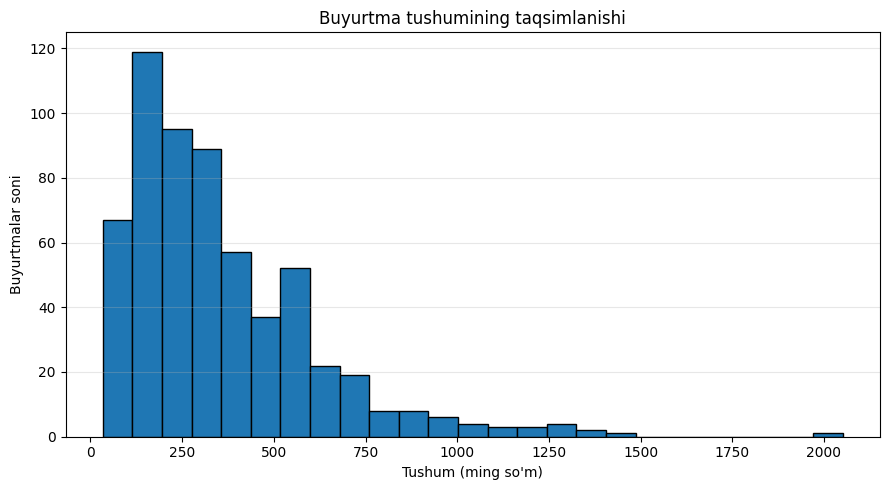

In [9]:
# 8. 1-GRAFIK: TUSHUM TAQSIMOTI

plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["tushum_uzs"] / 1000,
    bins=25,
    edgecolor="black"
)

plt.title("Buyurtma tushumining taqsimlanishi")
plt.xlabel("Tushum (ming so'm)")
plt.ylabel("Buyurtmalar soni")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("grafik1_tushum_taqsimoti.png", dpi=150)
plt.show()

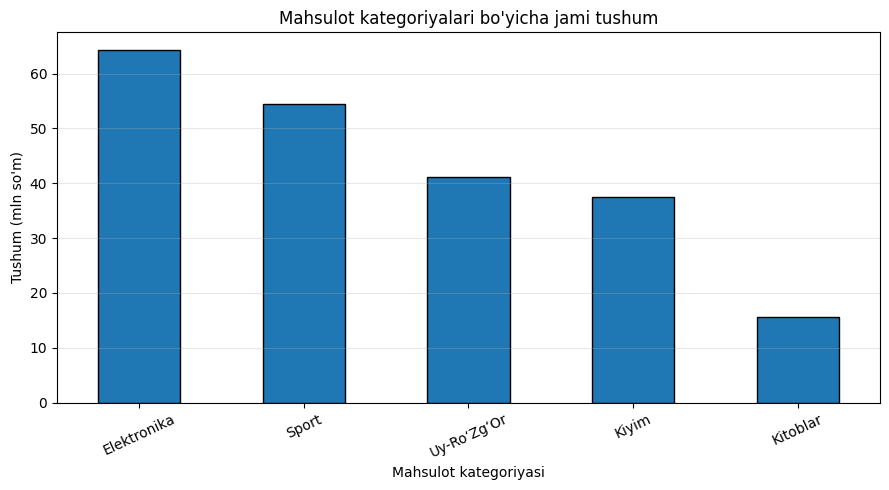

In [10]:
# 9. 2-GRAFIK: KATEGORIYALAR BO'YICHA TUSHUM

plt.figure(figsize=(9, 5))

(kategoriya_tahlili["jami_tushum"] / 1_000_000).plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Mahsulot kategoriyalari bo'yicha jami tushum")
plt.xlabel("Mahsulot kategoriyasi")
plt.ylabel("Tushum (mln so'm)")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("grafik2_kategoriya_tushumi.png", dpi=150)
plt.show()


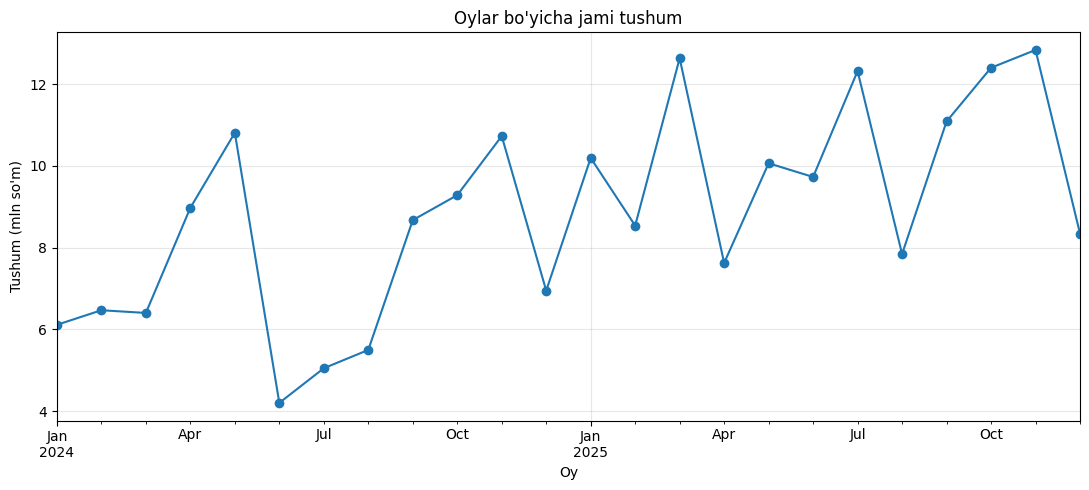

In [11]:
# 10. 3-GRAFIK: VAQT BO'YICHA TUSHUM

vaqt_df = df_clean.copy()
vaqt_df["sana"] = pd.to_datetime(vaqt_df["sana"])

oylik_tushum = (
    vaqt_df.set_index("sana")["tushum_uzs"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(11, 5))

(oylik_tushum / 1_000_000).plot(marker="o")

plt.title("Oylar bo'yicha jami tushum")
plt.xlabel("Oy")
plt.ylabel("Tushum (mln so'm)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("grafik3_vaqt_qatori.png", dpi=150)
plt.show()


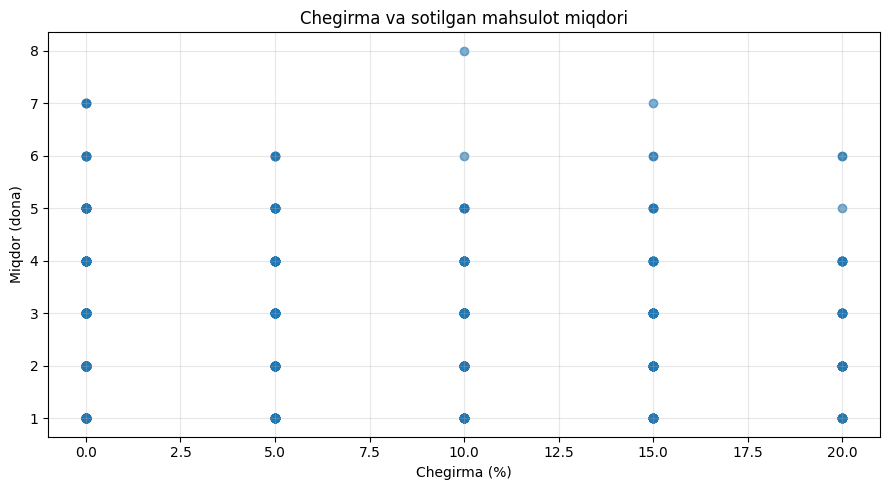

In [12]:
# 11. 4-GRAFIK: CHEGIRMA VA MIQDOR

plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean["chegirma_pct"],
    df_clean["miqdor"],
    alpha=0.6
)

plt.title("Chegirma va sotilgan mahsulot miqdori")
plt.xlabel("Chegirma (%)")
plt.ylabel("Miqdor (dona)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("grafik4_chegirma_miqdor.png", dpi=150)
plt.show()

In [13]:
# 12. NATIJALARNI EXCEL FAYLGA SAQLASH

with pd.ExcelWriter(
    "Amaliy_loyiha_1_qism_natijalar.xlsx",
    engine="openpyxl"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Xom_data",
        index=False
    )

    df_clean.to_excel(
        writer,
        sheet_name="Tozalangan_data",
        index=False
    )

    statistika.to_excel(
        writer,
        sheet_name="Statistika"
    )

    kategoriya_tahlili.to_excel(
        writer,
        sheet_name="Kategoriya"
    )

    hudud_tahlili.to_excel(
        writer,
        sheet_name="Hudud"
    )

    korrelyatsiya.to_excel(
        writer,
        sheet_name="Korrelyatsiya"
    )

print("\nLOYIHA MUVAFFAQIYATLI YAKUNLANDI!")
print("Tozalangan CSV, statistika, 4 ta grafik va Excel fayli yaratildi.")


LOYIHA MUVAFFAQIYATLI YAKUNLANDI!
Tozalangan CSV, statistika, 4 ta grafik va Excel fayli yaratildi.
